# Parametric primitives

Every mesh operation in meshio++ transforms a mesh you already have; `grid` was the
one exception. The **parametric primitives** build a shape from numbers, so a test, a
notebook or a demo needs no fixture file:

| generator | builds |
|---|---|
| `rectangle` | a 2-D grid of quads or triangles (`zigzag`, `up`, `down`, `center`) |
| `box` | a 3-D grid of hexahedra, tetrahedra or wedges |
| `disk` | a disk of quads (squircle map) or triangles (hexagonal rings) |
| `uv_sphere`, `icosa_sphere` | outward-oriented sphere surfaces |
| `cylinder` | a solid cylinder of hexahedra or wedges |
| `reference_triangle`, `ngon` | a refined reference triangle, a regular polygon |
| `annulus`, `lshape`, `plate_with_hole` | an annulus or a sector of one, the L-shaped domain, a plate around a hole |
| `honeycomb` | a tiling of hexagons as one ragged `polygon` block |
| `reference_cells` | one cell of each type in its reference coordinates |

They keep `grid`'s contract (coordinates computed from indices, a `max_cells` budget, an
empty mesh for a zero count), orient surfaces outward and volumes positively, return the
boundary as named `Side` regions, and with `order=2` place the mid-edge nodes on the
**exact geometry**. On the command line they are `meshioplusplus generate SHAPE OUTFILE`.

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp

import subprocess
import sys


def gl_available():
    # Can PyVista render off-screen here? VTK without a GL/EGL/OSMesa library aborts
    # the process instead of raising, so the probe runs in a child process.
    probe = ("import pyvista as pv; pv.OFF_SCREEN = True; "
             "pl = pv.Plotter(off_screen=True, window_size=(64, 64)); "
             "pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)")
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True, timeout=120).returncode == 0
    except Exception:
        return False


try:
    import pyvista as pv

    if gl_available():
        # Head-less, static rendering (no display / live server needed).
        pv.OFF_SCREEN = True
        pv.set_jupyter_backend('static')
    else:
        pv = None
        print('No GL available: rendering with matplotlib.')
except ImportError:  # pragma: no cover - pyvista is optional here
    pv = None
    print('PyVista unavailable: rendering with matplotlib.')

DOC_IMAGES = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), 'doc', 'public', 'images')


def show(img, title=None, figsize=(6, 4.5), save=None):
    """Embed a rendered RGB screenshot (and write it for the docs when `save` is set)."""
    if save:
        try:
            os.makedirs(DOC_IMAGES, exist_ok=True)
            plt.imsave(os.path.join(DOC_IMAGES, save + '.png'), img)
        except Exception as exc:  # pragma: no cover - read-only checkout
            print('doc image not written:', exc)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis('off')
    if title:
        plt.title(title)
    plt.tight_layout()
    plt.show()


def to_pyvista(mesh):
    """meshio++ Mesh -> pyvista grid via a temporary .vtu."""
    with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
        tmp = f.name
    try:
        mp.write(tmp, mesh)
        return pv.read(tmp)
    finally:
        os.unlink(tmp)


SURFACE_TYPES = {'triangle': 3, 'triangle6': 3, 'quad': 4, 'quad8': 4}


def surface_polygons(mesh):
    """The faces of a mesh as corner-node polygons (curved cells tessellated first)."""
    if any(b.type in ('triangle6', 'quad8', 'tetra10', 'hexahedron20', 'wedge15') for b in mesh.cells):
        mesh = mp.tessellate(mp.Mesh(mesh.points, mesh.cells), levels=3).mesh
    if not any(b.type in SURFACE_TYPES for b in mesh.cells):
        mesh = mp.extract_surface(mesh)
    polys = []
    for block in mesh.cells:
        if block.type in SURFACE_TYPES:
            polys += [mesh.points[row[:SURFACE_TYPES[block.type]]] for row in np.asarray(block.data)]
    return polys


def mpl_draw(ax, polys, color='#2ec4b6', edge='#1f4e79', lw=0.4):
    """matplotlib fallback: flat-shaded polygons in 3-D."""
    ax.add_collection3d(Poly3DCollection(polys, facecolor=color, edgecolor=edge, linewidths=lw, alpha=0.95))
    pts = np.concatenate(polys)
    lo, hi = pts.min(axis=0), pts.max(axis=0)
    centre, half = (lo + hi) / 2, (hi - lo).max() / 2
    ax.set_xlim(centre[0] - half, centre[0] + half)
    ax.set_ylim(centre[1] - half, centre[1] + half)
    ax.set_zlim(centre[2] - half, centre[2] + half)
    ax.set_box_aspect((1, 1, 1))
    ax.set_axis_off()
    ax.view_init(elev=22, azim=-55)


def render(mesh, title, color='#2ec4b6', save=None, figsize=(6, 4.5)):
    """PyVista off-screen render embedded through matplotlib; falls back to matplotlib alone."""
    if pv is not None:
        try:
            pl = pv.Plotter(off_screen=True, window_size=(900, 650))
            surf = to_pyvista(mesh).extract_surface(nonlinear_subdivision=3)
            pl.add_mesh(surf, color=color, show_edges=True, edge_color='#1f4e79', line_width=0.2)
            pl.camera_position = 'iso'
            img = pl.screenshot(return_img=True)
            pl.close()
            show(img, title, figsize=figsize, save=save)
            return
        except Exception as exc:  # head-less GL fallback
            print('PyVista render skipped, drawing with matplotlib:', type(exc).__name__)
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(projection='3d')
    mpl_draw(ax, surface_polygons(mesh), color=color)
    ax.set_title(title)
    plt.show()

No GL available: rendering with matplotlib.


## Rectangles and their triangle layouts

`rectangle(dims, size, origin, cell_type, split)` lays out a 2-D grid at `z = origin[2]`.
Quads are counter-clockwise; triangles split each quad `zigzag` (alternating diagonals,
the default), `up`, `down`, or `center` (four triangles around an added centre node).

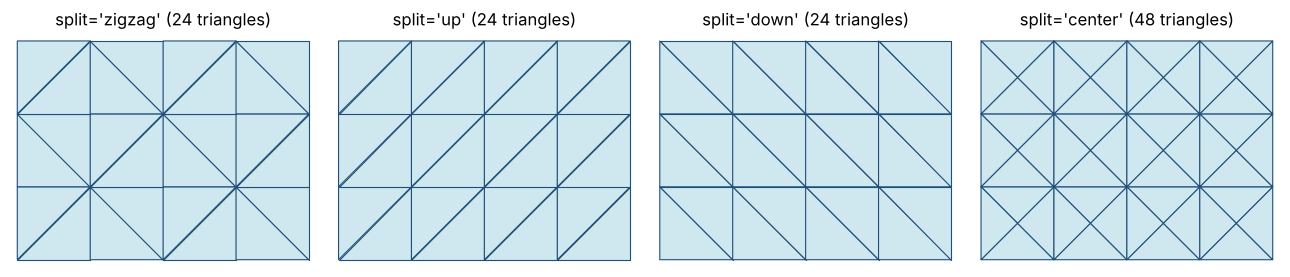

quads: 32 | sides: {'xmax': 4, 'xmin': 4, 'ymax': 8, 'ymin': 8}


In [2]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, split in zip(axes, ['zigzag', 'up', 'down', 'center']):
    m = mp.rectangle(dims=(4, 3), size=(4.0, 3.0), cell_type='triangle', split=split)
    tri = np.asarray(m.cells[0].data)
    ax.add_collection(PolyCollection(m.points[tri][:, :, :2], facecolor='#cfe8ef', edgecolor='#1f4e79', linewidths=0.8))
    ax.set_xlim(-0.1, 4.1); ax.set_ylim(-0.1, 3.1); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(f"split='{split}' ({len(tri)} triangles)")
plt.tight_layout()
plt.show()

q = mp.rectangle(dims=(8, 4), size=(2.0, 1.0))
print('quads:', len(q.cells[0].data), '| sides:', {r.name: len(r.entries) for r in q.regions})

## Boxes and their six side regions

`box` builds hexahedra, **tetrahedra** (the six Kuhn tetrahedra of each hexahedron around
its main diagonal, which conform across cells) or **wedges**. The boundary comes back as
the named `Side` regions `xmin` … `zmax`; each entry is a `(cell, local facet)` pair. Here
each hexahedral facet is coloured by its region.

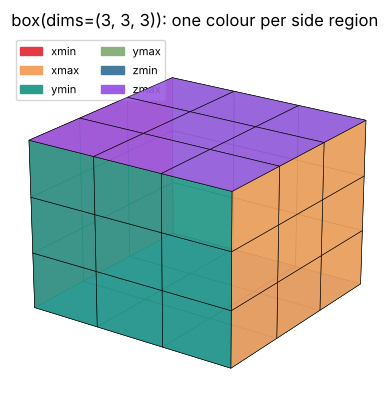

hexahedron    8 cells, 27 points
tetra        48 cells, 27 points
wedge        16 cells, 27 points


In [3]:
box = mp.box(dims=(3, 3, 3))
HEX_FACES = [(0, 4, 7, 3), (1, 2, 6, 5), (0, 1, 5, 4), (3, 7, 6, 2), (0, 3, 2, 1), (4, 5, 6, 7)]
palette = dict(xmin='#e63946', xmax='#f4a261', ymin='#2a9d8f', ymax='#8ab17d', zmin='#457b9d', zmax='#9b5de5')
conn = np.asarray(box.cells[0].data)

fig = plt.figure(figsize=(6, 4.8))
ax = fig.add_subplot(projection='3d')
for region in box.regions:
    polys = [box.points[conn[c, list(HEX_FACES[f])]] for c, f in region.entries]
    ax.add_collection3d(Poly3DCollection(polys, facecolor=palette[region.name], edgecolor='k', linewidths=0.4, alpha=0.9))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_zlim(0, 1); ax.set_axis_off(); ax.view_init(elev=22, azim=-55)
ax.set_title('box(dims=(3, 3, 3)): one colour per side region')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
ax.legend(handles, palette, loc='upper left', ncol=2, fontsize=8)
plt.show()

for cell_type in ('hexahedron', 'tetra', 'wedge'):
    m = mp.box(dims=(2, 2, 2), cell_type=cell_type)
    print(f"{cell_type:11s} {len(m.cells[0].data):3d} cells, {len(m.points)} points")

## Disks, spheres and cylinders

`disk` pushes an `n x n` grid onto the circle with the squircle map (`x' = r x sqrt(1 - y²/2)`),
or builds `n` rings of triangles. `uv_sphere` and `icosa_sphere` are oriented outward with welded
poles and seams. `cylinder` extrudes a disk into hexahedra or wedges and names its `side`, `top`
and `bottom` regions.

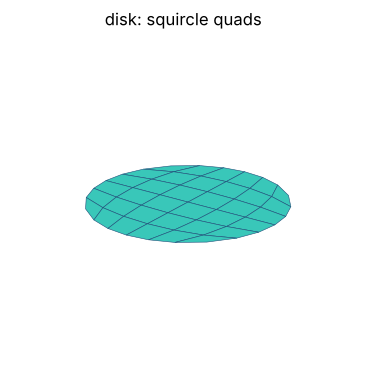

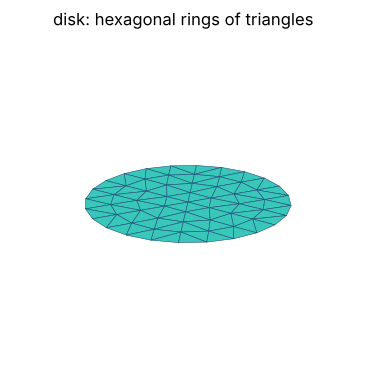

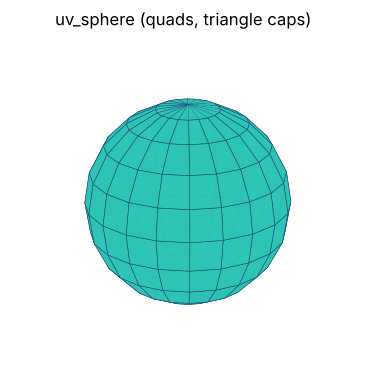

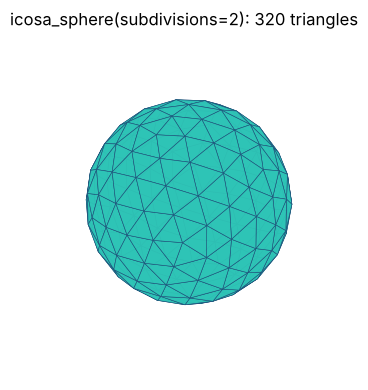

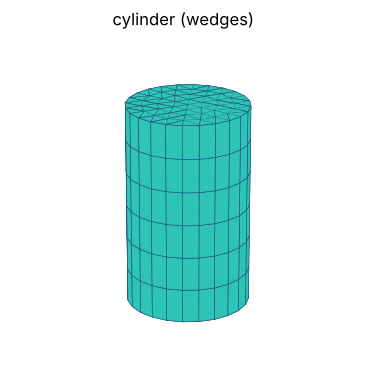

cylinder regions: {'bottom': 16, 'side': 96, 'top': 16}


In [4]:
render(mp.disk(radius=1.0, n=6), 'disk: squircle quads', save='primitives_disk')
render(mp.disk(radius=1.0, n=4, cell_type='triangle'), 'disk: hexagonal rings of triangles')
render(mp.uv_sphere(radius=1.0, nu=20, nv=10, cell_type='quad'), 'uv_sphere (quads, triangle caps)')
render(mp.icosa_sphere(radius=1.0, subdivisions=2), 'icosa_sphere(subdivisions=2): 320 triangles', save='primitives_icosa_sphere')
render(mp.cylinder(radius=0.6, height=2.0, nxy=4, nz=6, cell_type='wedge'), 'cylinder (wedges)', save='primitives_cylinder')
cyl = mp.cylinder(nxy=4, nz=6)
print('cylinder regions:', {r.name: len(r.entries) for r in cyl.regions})

## Planar domains

Six generators build the 2-D domains that refinement, error estimation and stress studies
start from, at `z = origin[2]`. `reference_triangle` is the reference triangle refined into
`n**2` triangles (it is not called `triangle`: `meshioplusplus.triangle` is the Triangle
file format); `ngon` fans a regular polygon from its centre; `annulus` is a ring, or a
**sector** whose two end rays stay separate node chains - the seam pair
[`periodic`](/periodic) links; `lshape` is the square minus a quadrant, a singular solution
at its re-entrant corner; `plate_with_hole` is the stress-concentration benchmark in four
quad blocks; `honeycomb` is a tiling of hexagons stored as one ragged `polygon` block. Each
boundary is a named side region, drawn here in its own colour.

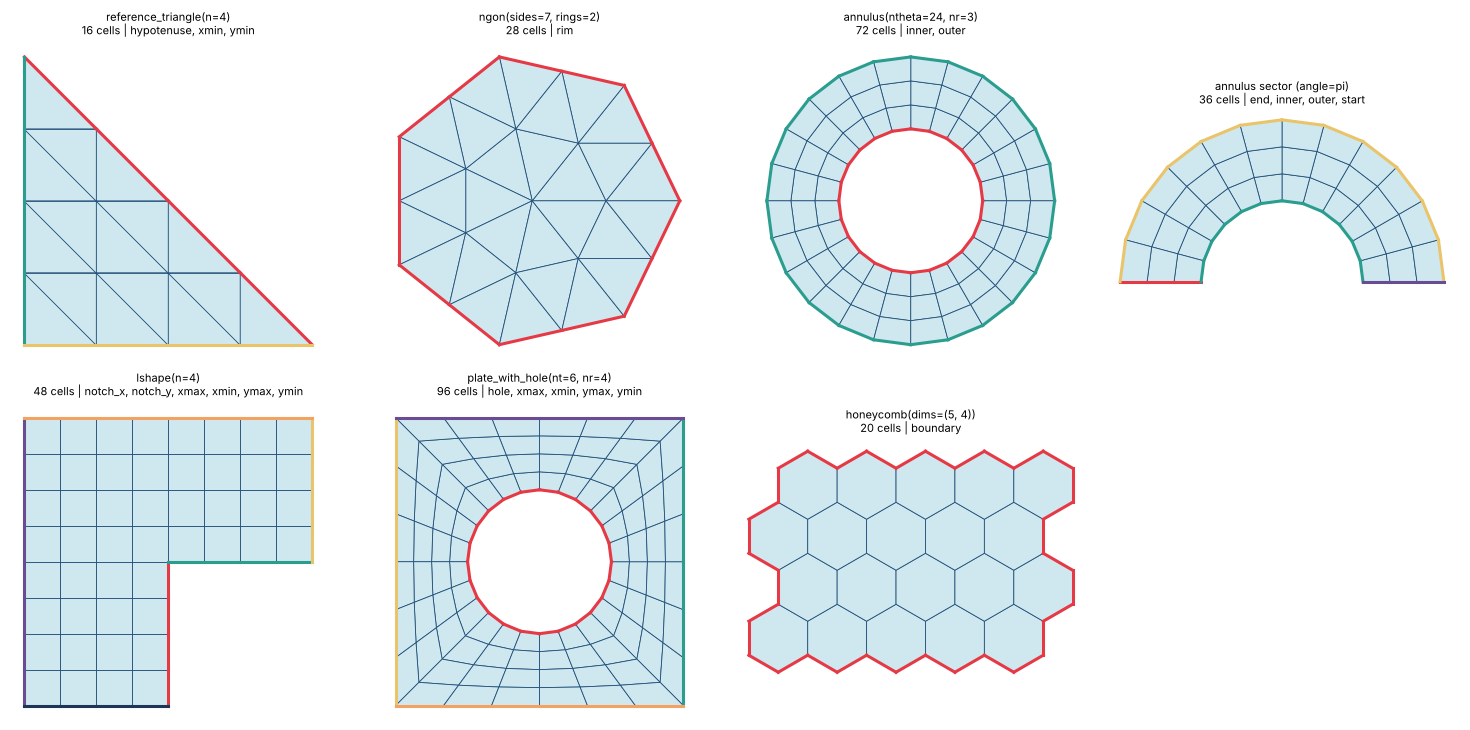

In [5]:
REGION_COLORS = ['#e63946', '#2a9d8f', '#e9c46a', '#6a4c93', '#f4a261', '#1d3557']
CORNERS = {'triangle': 3, 'quad': 4, 'triangle6': 3, 'quad8': 4, 'polygon': 6}


def cell_rows(mesh):
    """Every cell as its corner nodes, block after block (global cell order)."""
    rows = []
    for block in mesh.cells:
        k = CORNERS[block.type]
        rows += [list(map(int, row[:k])) for row in block.data]
    return rows


def draw_planar(ax, mesh, title):
    rows = cell_rows(mesh)
    xy = mesh.points[:, :2]
    ax.add_collection(PolyCollection([xy[r] for r in rows], facecolor='#cfe8ef', edgecolor='#1f4e79', linewidths=0.6))
    for color, reg in zip(REGION_COLORS, mesh.regions):
        for cell, facet in reg.entries:
            r = rows[cell]
            a, b = xy[r[facet]], xy[r[(facet + 1) % len(r)]]
            ax.plot([a[0], b[0]], [a[1], b[1]], color=color, lw=2.2)
    ax.autoscale_view()
    ax.set_aspect('equal'); ax.axis('off')
    names = ', '.join(r.name for r in mesh.regions)
    ax.set_title(f"{title}\n{len(rows)} cells | {names}", fontsize=8)


shapes = [
    ('reference_triangle(n=4)', mp.reference_triangle(n=4)),
    ('ngon(sides=7, rings=2)', mp.ngon(sides=7, rings=2)),
    ('annulus(ntheta=24, nr=3)', mp.annulus(0.5, 1.0, ntheta=24, nr=3)),
    ('annulus sector (angle=pi)', mp.annulus(0.5, 1.0, ntheta=12, nr=3, angle=np.pi)),
    ('lshape(n=4)', mp.lshape(n=4)),
    ('plate_with_hole(nt=6, nr=4)', mp.plate_with_hole(radius=0.25, size=1.0, nt=6, nr=4)),
    ('honeycomb(dims=(5, 4))', mp.honeycomb(dims=(5, 4), edge=0.5)),
]
fig, axes = plt.subplots(2, 4, figsize=(15, 7.4))
for ax, (title, m) in zip(axes.ravel(), shapes):
    draw_planar(ax, m, title)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

### What each shape promises

The checks below are the contract: counter-clockwise cells, welded seams, exact areas where
the geometry is polygonal, a **seam pair** on the sector, the L-shape's singular corner at the
centre, and `order=2` hole nodes that lie on the true circle (the linear hole is a polygon).

In [6]:
def region(mesh, name):
    return next(r for r in mesh.regions if r.name == name)


def signed_area(mesh):
    xy = mesh.points[:, :2]
    total, smallest = 0.0, np.inf
    for row in cell_rows(mesh):
        p = xy[row]
        a = 0.5 * np.sum(p[:, 0] * np.roll(p[:, 1], -1) - np.roll(p[:, 0], -1) * p[:, 1])
        total += a
        smallest = min(smallest, a)
    return total, smallest


for title, m in shapes:
    total, smallest = signed_area(m)
    print(f'{title:32s} area {total:8.4f}  smallest cell {smallest:+.4f}  points {len(m.points)}')

ring, sector = shapes[2][1], shapes[3][1]
print('\nfull ring welds its seam :', len(ring.points), '= 24 x 4 points, no start/end region:',
      [r.name for r in ring.regions])
start = np.unique(np.concatenate([np.asarray(sector.cells[0].data)[c][[f, (f + 1) % 4]] for c, f in region(sector, 'start').entries]))
end = np.unique(np.concatenate([np.asarray(sector.cells[0].data)[c][[f, (f + 1) % 4]] for c, f in region(sector, 'end').entries]))
print('sector keeps a seam pair :', 'start', 'nodes', start.tolist(), '| end nodes', end.tolist())

lshape = shapes[4][1]
print('\nL-shape: the node at the origin is the re-entrant corner:',
      bool(np.any(np.all(lshape.points == 0.0, axis=1))))

linear = mp.plate_with_hole(radius=0.25, size=1.0, nt=3, nr=2)
curved = mp.plate_with_hole(radius=0.25, size=1.0, nt=3, nr=2, order=2)
for label, m in (('order=1', linear), ('order=2', curved)):
    conn = np.asarray(m.cells[0].data)
    nodes = {int(conn[c][k]) for c, f in region(m, 'hole').entries for k in ((f, (f + 1) % 4) + ((4 + f,) if conn.shape[1] == 8 else ()))}
    r = np.linalg.norm(m.points[sorted(nodes), :2], axis=1)
    print(f'plate hole {label}: |r - 0.25| max {np.abs(r - 0.25).max():.2e} over {len(nodes)} hole nodes')

reference_triangle(n=4)          area   0.5000  smallest cell +0.0312  points 15
ngon(sides=7, rings=2)           area   2.7364  smallest cell +0.0977  points 22
annulus(ntheta=24, nr=3)         area   2.3294  smallest cell +0.0252  points 96
annulus sector (angle=pi)        area   1.1647  smallest cell +0.0252  points 52
lshape(n=4)                      area   3.0000  smallest cell +0.0625  points 65
plate_with_hole(nt=6, nr=4)      area   0.8059  smallest cell +0.0050  points 120
honeycomb(dims=(5, 4))           area  12.9904  smallest cell +0.6495  points 58

full ring welds its seam : 96 = 24 x 4 points, no start/end region: ['inner', 'outer']
sector keeps a seam pair : start nodes [0, 13, 26, 39] | end nodes [12, 25, 38, 51]

L-shape: the node at the origin is the re-entrant corner: True
plate hole order=1: |r - 0.25| max 0.00e+00 over 12 hole nodes
plate hole order=2: |r - 0.25| max 2.78e-17 over 24 hole nodes


## `order=2`: mid-edge nodes on the exact geometry

With `order=2` a generator returns serendipity cells (`triangle6`, `quad8`, `tetra10`,
`hexahedron20`, `wedge15`). Every mid-edge node is evaluated from the shape's own map, never
as a chord midpoint, so a coarse quadratic sphere is genuinely round. We check the radius
of every node and draw the cells [tessellated](/tessellation) so the curvature is visible.

linear   : 12 points, radii 2.0000 .. 2.0000
quadratic: 42 points, radii 2.0000 .. 2.0000


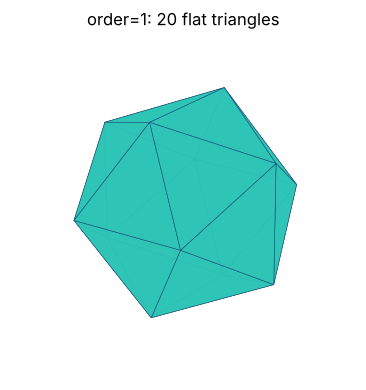

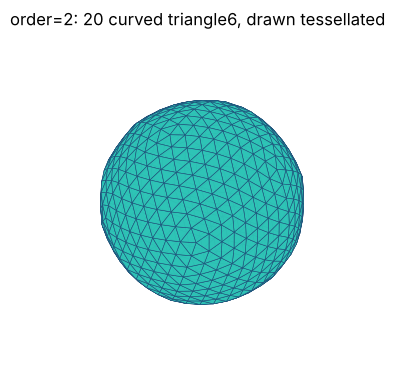

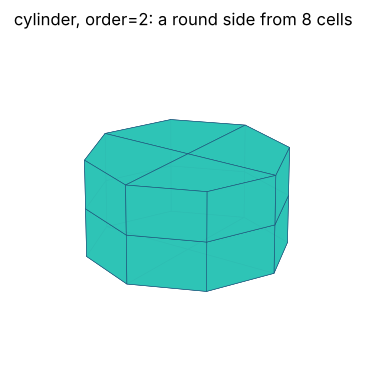

In [7]:
coarse = mp.icosa_sphere(radius=2.0, subdivisions=0)            # 20 flat triangles
curved = mp.icosa_sphere(radius=2.0, subdivisions=0, order=2)   # 20 curved triangle6

print('linear   : %d points, radii %.4f .. %.4f' % (len(coarse.points), np.linalg.norm(coarse.points, axis=1).min(), np.linalg.norm(coarse.points, axis=1).max()))
print('quadratic: %d points, radii %.4f .. %.4f' % (len(curved.points), np.linalg.norm(curved.points, axis=1).min(), np.linalg.norm(curved.points, axis=1).max()))

render(coarse, 'order=1: 20 flat triangles', save='primitives_sphere_order1')
render(curved, 'order=2: 20 curved triangle6, drawn tessellated', save='primitives_sphere_order2')
render(mp.cylinder(radius=1.0, height=1.0, nxy=2, nz=2, order=2), 'cylinder, order=2: a round side from 8 cells')

## Reference cells

`reference_cells(types)` returns one cell of each requested type in its reference
coordinates, laid out side by side without touching: the cheapest way to show a format's cell
coverage. With `pairs=True` it returns two cells that share a facet.

['triangle', 'quad', 'tetra', 'hexahedron', 'wedge', 'pyramid', 'triangle6', 'quad8', 'tetra10', 'hexahedron20', 'wedge15', 'pyramid13']
polyhedron block: polyhedron8


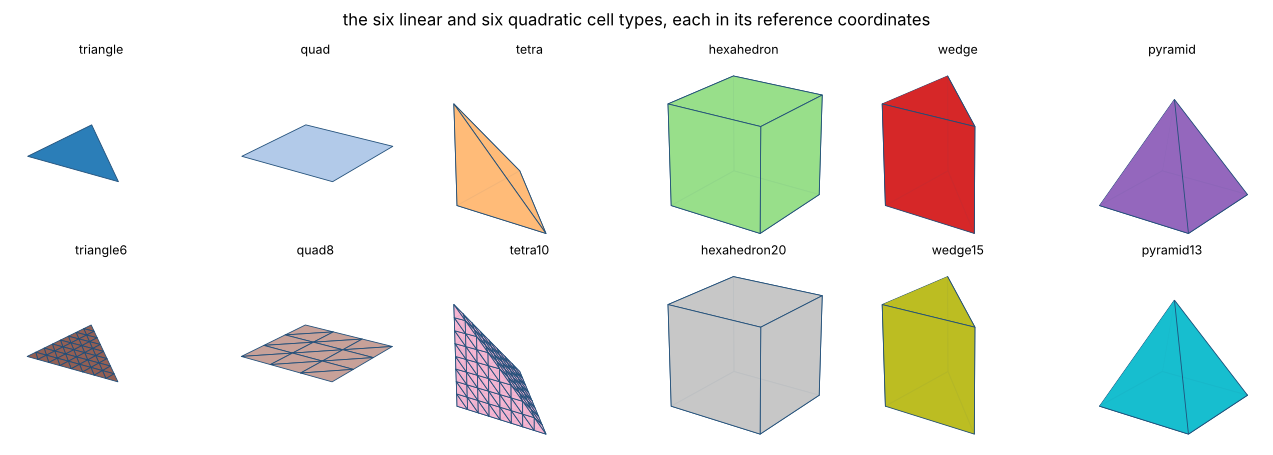

pairs: [('tetra', 2), ('hexahedron', 2)]


In [8]:
types = ['triangle', 'quad', 'tetra', 'hexahedron', 'wedge', 'pyramid',
         'triangle6', 'quad8', 'tetra10', 'hexahedron20', 'wedge15', 'pyramid13']
ref = mp.reference_cells(types)
print([b.type for b in ref.cells])
print('polyhedron block:', mp.reference_cells(['polyhedron']).cells[0].type)

fig = plt.figure(figsize=(13, 4.6))
for k, block in enumerate(ref.cells):
    ax = fig.add_subplot(2, 6, k + 1, projection='3d')
    single = mp.Mesh(ref.points, [(block.type, np.asarray(block.data))])
    mpl_draw(ax, surface_polygons(single), color=plt.cm.tab20(k / 12), lw=0.6)
    ax.set_title(block.type, fontsize=9)
plt.suptitle('the six linear and six quadratic cell types, each in its reference coordinates')
plt.tight_layout()
plt.show()

pairs = mp.reference_cells(['tetra', 'hexahedron'], pairs=True)
print('pairs:', [(b.type, len(b.data)) for b in pairs.cells])

## Cross-checks and the contract

The generators are cheap, so they make good oracles. Volumes are positive, `box` agrees
with `grid` for the same lattice, surfaces are closed, and an oversized request is refused
by name rather than by running out of memory.

In [9]:
b = mp.box(dims=(4, 3, 2), size=(4.0, 3.0, 2.0))
g = mp.grid([4, 3, 2])
print('box == grid:', np.allclose(b.points, g.points) and np.array_equal(b.cells[0].data, g.cells[0].data))

sphere = mp.icosa_sphere(subdivisions=3)
tri = np.asarray(sphere.cells[0].data)
edges = np.sort(np.concatenate([tri[:, [0, 1]], tri[:, [1, 2]], tri[:, [2, 0]]]), axis=1)
_, counts = np.unique(edges, axis=0, return_counts=True)
p = sphere.points
volume = np.einsum('ij,ij->i', p[tri[:, 0]], np.cross(p[tri[:, 1]], p[tri[:, 2]])).sum() / 6
print('icosa_sphere closed:', bool((counts == 2).all()), '| enclosed volume %.4f (4/3 pi = %.4f)' % (volume, 4 / 3 * np.pi))

try:
    mp.box(dims=(1000, 1000, 1000))
except ValueError as exc:
    print(exc)

box == grid: True
icosa_sphere closed: True | enclosed volume 4.1527 (4/3 pi = 4.1888)
meshio++: box: the requested mesh has 1000000000 cells, above the limit of 20000000 (raise max_cells or coarsen the counts)


## Beyond Python

The same generators are available from C (`mio_rectangle` … `mio_honeycomb`, `mio_reference_cells`), Fortran,
Julia, R and WASM, as `meshioplusplus generate box block.vtu --dims 8,8,8 --cell-type tetra`
on both command lines, as MCP tools, and as a pipeline source:

```json
{ "Version": 1,
  "Operations": [ { "Op": "Generate", "Shape": "box", "Dims": [8, 8, 8], "CellType": "tetra" } ],
  "Output": { "Path": "block.vtu" } }
```

See [parametric primitives](/primitives).